# Tuning stay_point v_1 (trên `dev`)

Chọn tham số của [`config.yaml`](config.yaml) theo từng bước. Mỗi bước: **định nghĩa** cái cần đo → **xét** (bảng / hình) → **output cho thấy** → **chọn**.
Bước sau dùng giá trị đã chọn ở bước trước. Diễn giải đầy đủ: [`docs/models/stay_point_v1.md`](../../../docs/models/stay_point_v1.md).

- Chỉ chạy trên `dev`. `holdout` không được mở trong notebook này.
- Chỉ số stay (định nghĩa ở `src/geolife/evaluation.py`): số stay / ngày có dữ liệu, `fragment_share` (stay là mảnh của lần dừng trước),
  `fake_share` (stay giả theo nhãn phương tiện).

| Bước | Tham số |
| --- | --- |
| B1 | Khoảng ứng viên của D (từ EDA) |
| B2 | Số stay theo (D, T) |
| B3 | T |
| B4 | D |
| B5 | max_gap |
| B6 | Khung đêm, khung hành chính |
| B7 | place_eps |
| B8 | min_nights, min_workdays |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from geolife import io
from geolife.calendar import WorkCalendar
from geolife.evaluation import label_flags, stay_metrics
from geolife.geo import haversine
from geolife.home_office import hour_slices, pick_roles, place_table, role_slices
from geolife.models import load_model
from geolife.models.stay_point import assign_places, detect_stays
from geolife.timezone import tz_country

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "axes.titleweight": "bold"})

base = load_model("stay_point", 1)
DV = base.data_version
users = io.split_users(DV, "dev")
pts = io.load_points(DV, users=users)
flags = label_flags(pts, io.load_labels(DV))
print(f"dev: {len(users)} user, {len(pts):,} điểm, {flags.labeled.sum():,} điểm có nhãn")


def run(D, T, gap=base.params["max_gap_h"]):
    st = detect_stays(pts, D, T, gap)
    return st, stay_metrics(st, pts, flags)

dev: 135 user, 18,452,398 điểm, 3,575,085 điểm có nhãn


## B1. Khoảng ứng viên của D

**Định nghĩa:** D là bán kính quanh điểm đầu của stay. D phải đủ lớn để chứa dao động của GPS khi user đứng yên, nếu không một lần dừng
sẽ bị chẻ thành nhiều mảnh.

**Xét:** EDA mục 14 đo bán kính chứa 90% số điểm trong 13.236 cửa sổ 10 phút đứng yên (dữ liệu thô):

| Phân vị | p50 | p75 | p90 | p95 | p99 |
| --- | --- | --- | --- | --- | --- |
| Bán kính p90 (m) | 16 | 32 | 71 | 149 | 746 |

**Output cho thấy:** D = 50 m chỉ chứa khoảng 3/4 số cửa sổ; D ≥ 150 m chứa 95%; phần đuôi tới hàng trăm mét là trong nhà / multipath.

**⇒ Ứng viên:** D ∈ {50, 100, 200, 300} m. EDA chỉ cho khoảng; giá trị được chọn ở B4 bằng chỉ số stay.

## B2. Khả năng tạo stay khi thay đổi D và T

**Định nghĩa:** số stay và số stay trên mỗi (user, ngày) có dữ liệu. Một người thường chỉ dừng ở vài nơi mỗi ngày, nên số stay / ngày quá cao
là dấu hiệu phân mảnh hoặc nhận nhầm lúc đang di chuyển là dừng. max_gap giữ ở giá trị khởi đầu (24 h), chọn lại ở B5.

In [2]:
grid = []
for D in [50, 100, 200, 300]:
    for T in [5, 10, 20, 30, 60]:
        _, m = run(D, T)
        grid.append({"D_m": D, "T_min": T, **m})
grid = pd.DataFrame(grid)
display(grid.pivot(index="D_m", columns="T_min", values="n_stays"))
display(grid.pivot(index="D_m", columns="T_min", values="stays_per_day"))

T_min,5,10,20,30,60
D_m,,,,,
50,32337,18279,10636,7894,4996
100,39110,23771,15253,11917,8086
200,45851,28632,19784,16203,11602
300,49638,30613,21818,18203,13473


T_min,5,10,20,30,60
D_m,,,,,
50,3.455,1.953,1.136,0.843,0.534
100,4.179,2.540,1.630,1.273,0.864
200,4.899,3.059,2.114,1.731,1.240
300,5.304,3.271,2.331,1.945,1.440


**Output cho thấy:**
- Số stay nhạy với T hơn nhiều so với D: tăng T từ 5 lên 60 phút làm số stay giảm 3–6 lần, còn tăng D từ 50 lên 300 m chỉ tăng 1,5–2,7 lần.
- Ở T = 5 phút có 3,5–5,3 stay mỗi ngày: quá nhiều so với nhịp sống bình thường, tức là có nhiều mảnh và nhiều lần dừng đèn đỏ / kẹt xe.

⇒ Chọn T trước (B3), rồi mới chọn D (B4).

## B3. Chọn T: tỉ lệ stay giả

**Định nghĩa:**
- Dùng nhãn phương tiện (chỉ có ở một phần user) để kiểm tra chéo.
- Stay "trong vùng có nhãn": ≥ 50% số điểm của stay nằm trong khoảng có nhãn.
- **Stay giả:** stay trong vùng có nhãn mà ≥ 50% số điểm mang nhãn **di chuyển**: phương tiện di chuyển, không tính `walk`: đi bộ loanh quanh trong một nơi (khuôn viên, trung tâm thương mại) vẫn là đang ở nơi đó.

**Xét:** với D = 100 và D = 200 (hai giá trị giữa của B1), thay đổi T.

T_min,5,10,20,30,60
D_m,,,,,
100,44.3%,43.0%,43.3%,45.4%,49.0%
200,46.9%,46.2%,46.9%,48.5%,52.1%


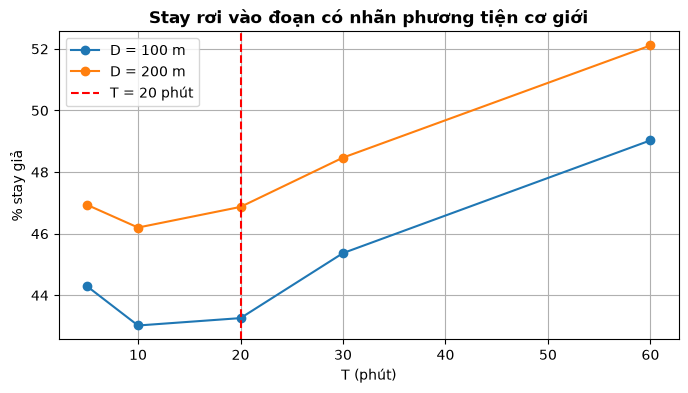

In [3]:
sub = grid[grid.D_m.isin([100, 200])]
display(sub.pivot(index="D_m", columns="T_min", values="fake_share").map("{:.1%}".format))
fig, ax = plt.subplots(figsize=(8, 4))
for D, g in sub.groupby("D_m"):
    ax.plot(g.T_min, g.fake_share * 100, "o-", label=f"D = {D} m")
ax.axvline(base.params["T_min"], color="r", ls="--", label=f"T = {base.params['T_min']} phút")
ax.set(xlabel="T (phút)", ylabel="% stay giả", title="Stay rơi vào đoạn có nhãn phương tiện cơ giới"); ax.legend(); plt.show()

**Output cho thấy:**
- Mức stay giả khá cao (43–52%). Một phần là nhiễu nhãn: khoảng nhãn `bike` / `car` thường trùm cả lúc xe đã dựng / đỗ và cả khoảng không ghi
  (EDA 12), nên chỉ số này chỉ dùng để **so sánh giữa các T**, không đọc như tỉ lệ lỗi thật.
- Từ T = 5 đến T = 20, stay giả gần như **không đổi** (D = 100: 44,3% → 43,0% → 43,3%; D = 200: 46,9% → 46,2% → 46,9%), chênh dưới 1 điểm %.
- Từ T = 30 trở đi stay giả **tăng rõ** (D = 200: 48,5% ở 30 phút, 52,1% ở 60 phút): T lớn loại bớt stay thật ngắn nhưng giữ lại các stay dài
  dưới nhãn di chuyển (xe dựng / đỗ lâu).

**⇒ Chọn T = 20 phút:** giá trị lớn nhất trước khi stay giả bắt đầu tăng. Trong vùng phẳng 5–20 phút, T lớn hơn cho ít stay vụn hơn
(B2: từ 3,06 xuống 2,11 stay / ngày khi T đi từ 10 lên 20 phút, D = 200) mà stay giả không tăng.

## B4. Chọn D: phân mảnh, stay giả và stay dài

**Định nghĩa:** với T đã chọn ở B3, xét ngược lại D bằng ba chỉ số:
- `fragment_share`: % stay là mảnh của lần dừng trước (bắt đầu ≤ 15 phút sau stay trước, tâm cách ≤ 250 m). Định nghĩa cố định, không phụ thuộc D.
- `fake_share`: như B3.
- `long_stays`: số stay ≥ 6 giờ. Thời gian ở nhà / ở chỗ làm nằm trong các stay dài, phần lớn kéo qua khoảng không ghi giữa hai file;
  điểm trước và sau khoảng không ghi thường lệch nhau nhiều hơn khi đứng yên liên tục, nên D quá nhỏ làm đứt các stay này.

In [4]:
T = base.params["T_min"]
d_tab = grid[grid.T_min == T].set_index("D_m")[["stays_per_day", "fragment_share", "fake_share", "long_stays"]]
display(d_tab.style.format({"stays_per_day": "{:.2f}", "fragment_share": "{:.1%}", "fake_share": "{:.1%}"}))

,stays_per_day,fragment_share,fake_share,long_stays
D_m,,,,
50,1.14,14.9%,43.0%,1702
100,1.63,14.1%,43.3%,3071
200,2.11,13.3%,46.9%,4829
300,2.33,11.6%,50.2%,5825


**Output cho thấy:**
- Phân mảnh giảm đều nhưng ít khi tăng D (14,9% → 11,6% từ 50 lên 300 m).
- Stay giả gần như không đổi tới 100 m (43,0% → 43,3%), rồi tăng khoảng 3,5 điểm % mỗi bước (46,9% ở 200 m, 50,2% ở 300 m).
- Nhưng số stay dài tăng rất mạnh tới 200 m (3.071 → 4.829, +57%), sau đó chậm lại (→ 5.825 ở 300 m, +21%). Stay dài là phần
  home / office cần: trên `dev`, user có home / office là 77 / 61 ở D = 100, 88 / 76 ở D = 200.

**⇒ Chọn D = 200 m:** đổi 3,6 điểm % stay giả lấy thêm hơn một nửa số stay dài. Lên 300 m thì lợi ích về stay dài nhỏ dần (+21%), trong khi
stay giả vẫn tăng cùng mức và bán kính bắt đầu gộp hai nơi khác nhau. Khớp với EDA (B1): 200 m chứa p95 dao động khi đứng yên (149 m).

## B5. Chọn max_gap: sau một khoảng không ghi, user có còn ở đúng chỗ cũ không?

**Định nghĩa:** stay được phép kéo qua khoảng không ghi giữa hai điểm (thường là giữa hai file), vì phần lớn thời gian ở nhà / ở chỗ làm
nằm trong các khoảng này (EDA mục 6). Nhưng khoảng không ghi càng dài thì càng ít bằng chứng user đã ở yên.

**Xét:**
1. Với mọi cặp điểm liên tiếp có khoảng không ghi ≥ 10 phút: % cặp mà điểm sau cách điểm trước ≤ D ("quay lại đúng chỗ")
2. Chỉ số stay theo max_gap.

In [5]:
D = base.params["D_m"]
ts = pts.ts_utc.to_numpy().astype("datetime64[s]").astype(np.int64)
same_user = pts.user.to_numpy()[1:] == pts.user.to_numpy()[:-1]
dt_h = np.diff(ts) / 3600
d = haversine(pts.lat.to_numpy()[:-1], pts.lon.to_numpy()[:-1], pts.lat.to_numpy()[1:], pts.lon.to_numpy()[1:])
gp = pd.DataFrame({"dt_h": dt_h, "back": d <= D})[same_user & (dt_h >= 1 / 6)]
bins = [1 / 6, 1, 3, 6, 12, 24, 48, 72, 168, 1e6]
gp["bin"] = pd.cut(gp.dt_h, bins, labels=["10'-1h", "1-3h", "3-6h", "6-12h", "12-24h", "24-48h", "48-72h", "3-7 ngày", "> 7 ngày"])
ret = gp.groupby("bin", observed=True).agg(gaps=("back", "size"), back_share=("back", "mean"))
display(ret.style.format({"back_share": "{:.1%}"}))
rows = []
for g in [6, 12, 24, 48, 72, 1e6]:
    _, m = run(D, T, g)
    rows.append({"max_gap_h": g, **m})
display(pd.DataFrame(rows).set_index("max_gap_h")[["stays_per_day", "fragment_share", "fake_share", "long_stays"]]
        .style.format({"fragment_share": "{:.1%}", "fake_share": "{:.1%}", "stays_per_day": "{:.2f}"}))

,gaps,back_share
bin,,
10'-1h,14174,72.0%
1-3h,5329,61.0%
3-6h,2749,47.3%
6-12h,5149,44.4%
12-24h,4781,31.8%
24-48h,1163,22.4%
48-72h,339,18.6%
3-7 ngày,384,18.0%
> 7 ngày,307,17.6%


,stays_per_day,fragment_share,fake_share,long_stays
max_gap_h,,,,
6.000000,1.65,15.5%,41.7%,161
12.000000,1.92,14.0%,45.7%,2888
24.000000,2.11,13.3%,46.9%,4829
48.000000,2.14,13.2%,46.9%,5133
72.000000,2.15,13.2%,46.8%,5210
1000000.000000,2.17,13.2%,46.8%,5356


**Output cho thấy:**
- Tỉ lệ quay lại đúng chỗ giảm dần theo độ dài khoảng không ghi: 72% (< 1 h), 44% (6–12 h), 32% (12–24 h), rồi 22% (24–48 h).
- Từ 24 h trở đi tỉ lệ này gần như đứng yên quanh 18–22%, tức là ngang mức "tình cờ": sau hơn một ngày, việc user ở đúng chỗ cũ không còn
  nói gì về việc họ đã ở yên suốt khoảng đó (phần lớn chỉ là đã về nhà).
- Chỉ số stay cũng bão hoà sau 24 h: tăng max_gap từ 24 lên 48 h chỉ thêm 6% số stay dài (4.829 → 5.133); phân mảnh và stay giả không đổi (13,3% → 13,2%, 46,9% → 46,9%).
  Ngược lại, hạ xuống 12 h làm mất 40% số stay dài (→ 2.888): mất các đêm dài.

**⇒ Chọn max_gap = 24 h.**

## B6. Khung đêm và khung hành chính

**Định nghĩa:** không giả định trước khung giờ, mà nhìn vào chính các stay dài:
- **Stay qua đêm:** dài 6–24 giờ và có chứa 03:00 local.
- **Stay ban ngày của ngày làm việc:** bắt đầu từ 06:00, kết thúc trước 22:00 trong cùng ngày, dài ≥ 3 giờ, rơi vào ngày làm việc
  (lịch của đúng quốc gia, có ngày nghỉ lễ và ngày làm bù).

Với mỗi giờ trong ngày, đo % số stay của loại đó phủ giờ này (phủ ít nhất 30 phút). Tính theo từng user (user có ≥ 3 stay loại đó) rồi lấy
trung bình giữa các user, để vài power user không lấn át.

**Quy tắc chọn:**
- **Khung đêm** = các giờ được ≥ **60%** số stay qua đêm phủ. Ngưỡng chặt hơn vì giờ ngủ khá đồng đều giữa mọi người, và khung đêm
  quyết định home: chỉ nên lấy phần lõi của đêm.
- **Khung hành chính** = các giờ được ≥ **40%** số stay ban ngày phủ. Ngưỡng nhẹ hơn vì giờ đến / về chỗ làm lệch nhau nhiều giữa mọi người
  (người đến 8h, người 10h); ngưỡng cao sẽ cắt mất đầu / cuối ngày làm việc của nhiều người.

Bước này chỉ dùng stay (B1–B5), chưa cần place, nên làm trước khi chọn place_eps (B7).

Stay qua đêm: 3136 stay của 81 user
Stay ban ngày, ngày làm việc: 1762 stay của 66 user


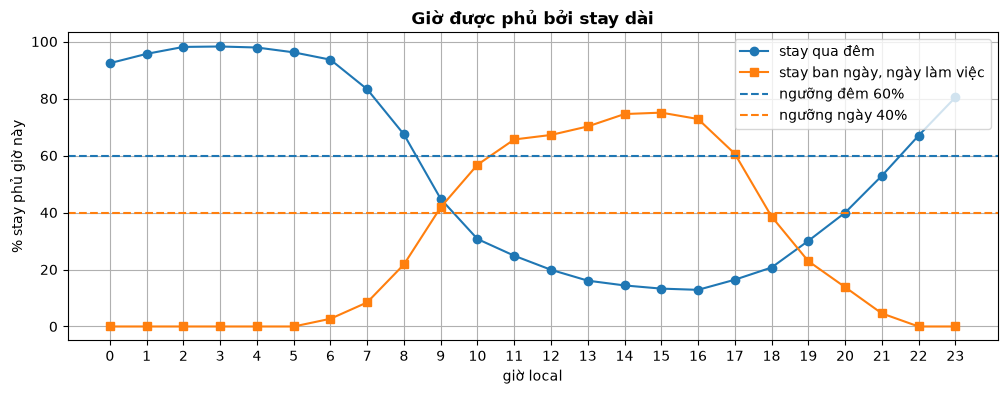

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
qua đêm,92,96,98,98,98,96,94,83,67,45,...,14,13,13,16,21,30,40,53,67,80
"ban ngày, ngày làm việc",0,0,0,0,0,0,3,8,22,42,...,75,75,73,61,39,23,14,5,0,0


Giờ được >= 60% stay qua đêm phủ: [0, 1, 2, 3, 4, 5, 6, 7, 8, 22, 23]
Giờ được >= 40% stay ban ngày phủ: [9, 10, 11, 12, 13, 14, 15, 16, 17]
Config: [22, 9] [9, 18]


In [6]:
stays, _ = run(D, T, base.params["max_gap_h"])
cal = WorkCalendar(np.unique(tz_country(stays.tz.unique())), range(2006, 2014))
vid, h, hb = hour_slices(stays.start_local.to_numpy(), stays.end_local.to_numpy())
sl = pd.DataFrame({"vid": vid, "user": stays.user.to_numpy()[vid], "hour": (hb % 24).astype(int), "h": h})
sday = np.floor(stays.start_local / 86400).astype(np.int64); eday = np.floor(stays.end_local / 86400).astype(np.int64)
sh, eh = (stays.start_local % 86400) / 3600, (stays.end_local % 86400) / 3600
overnight = stays.index.isin(sl.vid[sl.hour == 3].unique()) & stays.dur_h.between(6, 24)
daytime = ((sday == eday) & (sh >= 6) & (eh <= 22) & (stays.dur_h >= 3)
           & cal.is_workday(tz_country(stays.tz.to_numpy()), sday.to_numpy())).to_numpy()


def coverage(mask):
    s = sl[np.isin(sl.vid, np.flatnonzero(mask)) & (sl.h >= 0.5)]
    c = s.groupby(["user", "hour"]).vid.nunique().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
    n = stays[mask].groupby("user").size().reindex(c.index)
    return c.div(n, axis=0)[n >= 3].mean(), int((n >= 3).sum()), int(mask.sum())


cov = {}
for name, mk in [("qua đêm", overnight), ("ban ngày, ngày làm việc", daytime)]:
    cov[name], nu, ns = coverage(mk)
    print(f"Stay {name}: {ns} stay của {nu} user")
cov = pd.DataFrame(cov)
fig, ax = plt.subplots(figsize=(12, 4))
for c, m in zip(cov.columns, ["o-", "s-"]):
    ax.plot(cov.index, cov[c] * 100, m, label=f"stay {c}")
NIGHT_MIN, DAY_MIN = 0.6, 0.4
ax.axhline(NIGHT_MIN * 100, color="C0", ls="--", label="ngưỡng đêm 60%")
ax.axhline(DAY_MIN * 100, color="C1", ls="--", label="ngưỡng ngày 40%")
ax.set(xlabel="giờ local", ylabel="% stay phủ giờ này", xticks=range(24), title="Giờ được phủ bởi stay dài"); ax.legend(); plt.show()
display((cov.T * 100).round(0).astype(int))
night_h = [hh for hh in range(24) if cov["qua đêm"][hh] >= NIGHT_MIN]
day_h = [hh for hh in range(24) if cov["ban ngày, ngày làm việc"][hh] >= DAY_MIN]
print("Giờ được >= 60% stay qua đêm phủ:", night_h)
print("Giờ được >= 40% stay ban ngày phủ:", day_h)
print("Config:", base.params["night_hours"], base.params["work_hours"])

**Output cho thấy:**
- Stay qua đêm phủ ≥ 80% các giờ 23:00–07:00. Giờ đạt ngưỡng 60% là **22:00 (67%) tới hết 08:00 (67%)**; 21:00 (53%) và 09:00 (45%) không đạt.
- Stay ban ngày của ngày làm việc phủ ≥ 57% các giờ 10:00–17:00. Giờ đạt ngưỡng 40% là **09:00 (42%) tới hết 17:00 (61%)**; 18:00 (39%) không đạt.
- Hai khung không chồng lên nhau.

**⇒ Chọn:** khung đêm **[22, 9)**, áp cho mọi ngày, kể cả ngày nghỉ lễ và cuối tuần (đêm nào cũng về nhà). Khung hành chính **[9, 18)**,
chỉ áp cho ngày làm việc, nên ngày làm bù được tính, còn ngày nghỉ lễ rơi vào T2–T6 thì không.

## B7. Chọn place_eps: gom stay thành place

**Định nghĩa:** các stay của cùng user được gom thành place: lấy stay dài nhất làm tâm, kéo mọi stay chưa gán trong bán kính place_eps
(`assign_places` trong `src/geolife/models/stay_point.py`). Home / office là một place. place_eps quá nhỏ thì một nơi bị chia thành nhiều place, giờ bị chia ra và
home có thể nhảy sang nơi khác; quá lớn thì hai nơi khác nhau (nhà và quán cà phê đầu ngõ) bị gộp làm một.

**Xét:** dùng khung giờ đã chọn ở B6. Số place trên mỗi user, số user có home / office, và % user có toạ độ home / office thay đổi > 200 m so với place_eps liền trước.

In [7]:
model = load_model("stay_point", 1)
prev, rows = None, []
for eps in [50, 100, 200, 300, 500]:
    model.params["place_eps_m"] = eps
    st, places, pred = model.label(stays, users)
    p = pred.set_index(["user", "role"])
    r = {"eps_m": eps, "places_per_user": places.groupby("user").size().median(),
         "home_found": int(p.xs("home", level="role").lat.notna().sum()), "office_found": int(p.xs("office", level="role").lat.notna().sum())}
    if prev is not None:
        j = p.join(prev.add_suffix("_prev")).dropna(subset=["lat", "lat_prev"])
        moved = haversine(j.lat, j.lon, j.lat_prev, j.lon_prev) > 200
        for role in ["home", "office"]:
            r[f"{role}_moved_vs_prev"] = moved[j.index.get_level_values("role") == role].mean()
    rows.append(r); prev = p[["lat", "lon"]]
display(pd.DataFrame(rows).set_index("eps_m").style.format({"home_moved_vs_prev": "{:.1%}", "office_moved_vs_prev": "{:.1%}"}, na_rep="-"))
model.params["place_eps_m"] = base.params["place_eps_m"]

,places_per_user,home_found,office_found,home_moved_vs_prev,office_moved_vs_prev
eps_m,,,,,
50,25.000000,74,54,-,-
100,19.000000,85,63,9.5%,13.0%
200,14.500000,88,76,2.4%,4.8%
300,13.000000,88,78,3.4%,6.7%
500,11.000000,89,75,4.5%,5.3%


**Output cho thấy:**
- place_eps nhỏ (50 m) chia một nơi thành nhiều place: chỉ 74 user có home, 54 user có office.
- Từ 100 lên 200 m, home và office đều ổn định nhất: chỉ 2,4% user đổi toạ độ home > 200 m, 4,8% đổi office.
  Số user có home đạt mức trần (88, không tăng ở 300 m).
- Từ 200 m trở lên, home lại bắt đầu dịch (3,4% rồi 4,5%) vì bán kính lớn gộp nhà với các nơi gần nhà.

**⇒ Chọn place_eps = 200 m:** vùng ổn định nhất của cả home và office, cùng thang đo với D.

## B8. Cần bao nhiêu đêm / ngày làm việc để tin được home / office?

**Định nghĩa:** với user có nhiều dữ liệu (≥ 20 đêm ở home, ≥ 20 ngày làm việc ở office), lấy home / office tính từ **toàn bộ** dữ liệu làm
mốc. Rút ngẫu nhiên k đêm (hoặc k ngày làm việc), chỉ dùng giờ trong k đêm đó để chọn lại home / office, rồi đo % lần trùng mốc (cùng place).
Lặp 30 lần cho mỗi user và mỗi k.

**Xét:** k ∈ {1, 2, 3, 5, 10}.

In [8]:
st, _, _ = model.label(stays, users)
rs = role_slices(st, cal, tuple(base.params["night_hours"]), tuple(base.params["work_hours"]))
ptab = place_table(st, rs)
full = pick_roles(ptab, users, 1, 1, base.params["same_place_m"]).set_index(["user", "role"])
# office không được rơi vào vùng quanh home (như trong model): bỏ trước các place cách home <= same_place_m
hm = full.xs("home", level="role")[["lat", "lon"]].rename(columns={"lat": "hlat", "lon": "hlon"})
pj = ptab.join(hm, on="user")
near_home = set(map(tuple, pj.loc[haversine(pj.lat, pj.lon, pj.hlat, pj.hlon) <= base.params["same_place_m"], ["user", "place"]].to_numpy()))
rng = np.random.default_rng(0)
rows = []
for role, flag, dcol in [("home", "home", "night_day"), ("office", "office", "day")]:
    r = rs[rs[flag]]
    if role == "office":
        r = r[[(a, b) not in near_home for a, b in zip(r.user, r.place)]]
    for u, g in r.groupby("user"):
        ref = full.loc[(u, role), "place"]
        days = g[dcol].unique()
        if ref < 0 or len(days) < 20:
            continue
        for k in [1, 2, 3, 5, 10]:
            hit = 0
            for _ in range(30):
                sub = g[g[dcol].isin(rng.choice(days, k, replace=False))]
                hit += sub.groupby("place").h.sum().idxmax() == ref
            rows.append({"role": role, "user": u, "k": k, "match": hit / 30})
mt = pd.DataFrame(rows)
display(mt.groupby(["role", "k"]).agg(users=("user", "nunique"), match=("match", "mean")).unstack("role")
        .style.format({("match", "home"): "{:.0%}", ("match", "office"): "{:.0%}"}))

**Output cho thấy:**
- Với 1 đêm / 1 ngày làm việc, home / office chỉ trùng mốc 48–49%: không hơn đoán.
- Độ trùng tăng nhanh ở vài đêm đầu (3 đêm: 61% home, 64% office), rồi chậm lại (10 đêm: 84% / 80%).

**⇒ Chọn min_nights = min_workdays = 3:** mốc đầu tiên mà cả hai vai trò đều trùng ≥ 60%. Dưới mốc này model trả `null` kèm lý do (abstain)
thay vì đoán. Đây là mức tối thiểu, không phải mức tin cậy cao: với 3 đêm vẫn còn khoảng 2/5 trường hợp khác với khi có đủ dữ liệu.

## Tổng kết

Giá trị chọn ở từng bước được ghi vào `config.yaml`. Ô cuối cùng chạy model với tham số này trên `holdout` (một lần), ghi kết quả vào `results/data_v1/stay_point_v1/holdout/`, rồi đăng ký version này lên MLflow (cần MLflow đang chạy: `make up`; version đã đăng ký thì bỏ qua).

In [9]:
print(base.params)

{'D_m': 200, 'T_min': 20, 'max_gap_h': 24, 'place_eps_m': 200, 'night_hours': [22, 9], 'work_hours': [9, 18], 'min_nights': 3, 'min_workdays': 3, 'same_place_m': 200, 'confidence': {'n_boot': 200, 'block': 'week', 'seed': 0}}


In [ ]:
from geolife import register, run

run.main(["--model", "stay_point", "--version", "1", "--split", "holdout"])
register.main(["--model", "stay_point", "--version", "1"])